In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [4]:
con = duckdb.connect()
con.read_parquet("../Data/Processed/orders_clean.parquet").create_view("orders");


In [ ]:
a = con.execute(""" select *
            from orders """).df()
a.iloc[0:2]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_carrier_before_purchase,flag_customer_before_carrier,...,flag_approval_after_carrier,order_year,order_month,order_day,order_weekday,delivery_duration_days,delivery_delay_days,is_late,approval_hours,carrier_to_customer_days
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,False,False,...,False,2017,2,21,Tuesday,209.628611,181,True,27.063333,195.033947


### delivery duration analysis

In [ ]:
delivery_time = con.sql(""" 
    select 
        order_id,
        order_purchase_timestamp,
        order_delivered_customer_date,
        delivery_duration_days
    from orders
    where order_status = 'delivered'
        and order_purchase_timestamp is not null
        and order_delivered_customer_date is not null
""").df()


In [28]:
print("orders with their delivery time:")
display(delivery_time.head(10))

orders with their delivery time:


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-09 21:57:05,2017-07-26 10:57:55,16.542245
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-16 13:10:30,2017-05-26 12:55:51,9.989826
7,76c6e866289321a7c93b82b54852dc33,2017-01-23 18:29:09,2017-02-02 14:08:10,9.818762
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-07-29 11:55:02,2017-08-16 17:14:30,18.221852
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-16 19:41:10,2017-05-29 11:18:31,12.650937


In [30]:
#Statistical calculations
cal = delivery_time["delivery_duration_days"].describe().to_frame().round(1)
display(delivery_time["delivery_duration_days"].describe().to_frame().round(1))
print(f"longest delivery time : {cal.loc['max', 'delivery_duration_days']} days")
print(f"shortest delivery time : {cal.loc['min', 'delivery_duration_days']} days")
print(f"average delivery time : {cal.loc['mean', 'delivery_duration_days']} days")

,delivery_duration_days
count,96470.0
mean,12.6
std,9.5
min,0.5
25%,6.8
50%,10.2
75%,15.7
max,209.6


longest delivery time : 209.6 days
shortest delivery time : 0.5 days
average delivery time : 12.6 days


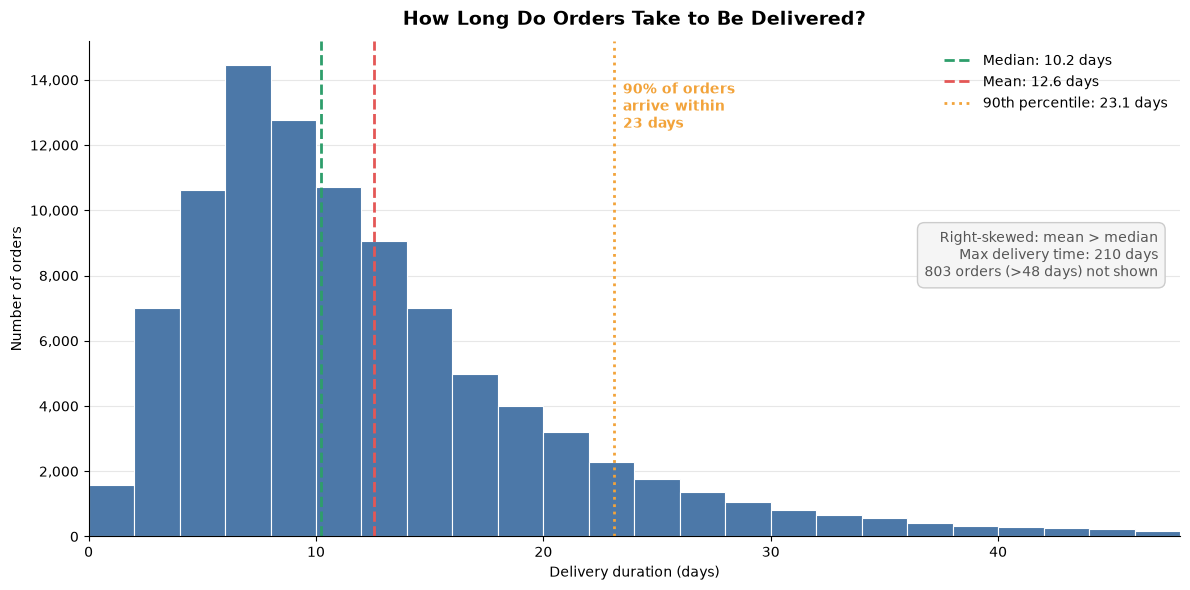

In [40]:

d = delivery_time["delivery_duration_days"]

mean, median = d.mean(), d.median()
p90, p95 = d.quantile(0.90), d.quantile(0.95)

# Zoom to the range that holds ~99% of orders; count the rest separately
cap = np.ceil(d.quantile(0.99) / 2) * 2   # round up to a multiple of the bin width
n_beyond = (d > cap).sum()

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    d[d <= cap],
    bins=np.arange(0, cap + 2, 2),   # 2-day wide bins
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.8,
)

# Reference lines
ax.axvline(median, color="#2E9E6B", linestyle="--", linewidth=2, label=f"Median: {median:.1f} days")
ax.axvline(mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean: {mean:.1f} days")
ax.axvline(p90, color="#F2A33A", linestyle=":", linewidth=2, label=f"90th percentile: {p90:.1f} days")

# Note about the long right tail
ax.text(
    0.98, 0.62,
    f"Right-skewed: mean > median\n"
    f"Max delivery time: {d.max():.0f} days\n"
    f"{n_beyond:,} orders (>{cap:.0f} days) not shown",
    transform=ax.transAxes, ha="right", va="top", fontsize=10, color="#555555",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="#CCCCCC"),
)
ax.text(p90 + 0.4, ax.get_ylim()[1] * 0.92, "90% of orders\narrive within\n23 days",
        color="#F2A33A", fontsize=10, fontweight="bold", va="top")

ax.set_title("How Long Do Orders Take to Be Delivered?", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Delivery duration (days)")
ax.set_ylabel("Number of orders")
ax.set_xlim(0, cap)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(frameon=False, fontsize=10, loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Business Conclusion – Delivery Duration Overview

The analysis of 96,470 successfully delivered orders reveals that the average delivery time is **12.6 days**, while the median delivery time is **10.2 days**. This difference suggests a positively skewed distribution, indicating that a number of orders with unusually long delivery durations increase the overall average.

The standard deviation of **9.5 days** also indicates considerable variability in delivery times, meaning that customers do not experience a consistent delivery duration.

The distribution analysis provides further insights:

- The middle 50% of orders(IQR) were delivered within **6.8 to 15.7 days**.
- **90% of orders** were delivered within approximately 23.1 days.(a useful “worst typical case” number and the 90th percentile is the better number for setting customer expectations)
- A relatively small proportion (about 1%) of orders experienced significantly longer delivery durations ( more than 48 days) with the maximum reaching approximately **210 days**.

The histogram confirms a right-skewed distribution, with most orders concentrated in shorter delivery intervals and a long tail representing delayed deliveries.

**Business Implications:**

Although the majority of customers receive their orders within a relatively reasonable time frame, the existence of extremely long delivery durations indicates potential operational issues affecting a smaller group of orders.

These extreme cases may negatively affect customer experience and should be investigated further.

However, this analysis alone does not identify the causes of long delivery times. Further investigation across different states and delivery periods is necessary to determine whether these delays are concentrated in specific regions or occur more broadly across the business.

**Overall, delivery performance appears reasonably concentrated for most orders, but significant variability and extreme delays remain important areas for operational improvement.**